## Project: Labels vs. Scale: Breaking Even on Banking77 with Encoders and Decoders

**ModernBERT-base on Colab (G4 GPU)**: full fine-tuning (no LoRA) on every training budget and seed, under two epoch rules:

- **fixed3 (main):** every budget trains exactly 3 epochs, the same rule as the Qwen runs. Saved as model `modernbert`.
- **min300 (variant):** at least 300 optimizer steps per run (3 to 50 epochs). Shows whether small-budget results depend on training length. Saved as model `modernbert_min300`.

Each rule has its own learning-rate pilot at k10 (the best value depends on the number of steps). Run the cells from top to bottom: setup, smoke test, then the whole main protocol, then the variant. Everything uses the model after the final epoch.

Results go to Google Drive. If the session disconnects, reconnect, run **Setup** again, then run the **Run all** cell again: finished runs are skipped and training continues with the first unfinished one.

#### Setup

If you upload a newer version of a script to Drive, restart the session (Runtime, Restart session) and run Setup again, so Python loads the new version.

Mount Google Drive. Everything that must survive a disconnect (data backup, predictions, logs) lives there.

In [1]:
# Mount Google Drive (a pop-up asks for permission the first time)
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


#### Paths and code

The code and data live on Drive and are copied to Colab's fast local disk at the start of every session. Only the results are written straight back to Drive.

In [2]:
import os
import shutil

PROJECT = "/content/banking77"                      # Local copy of the repo (lost when the session ends)
DRIVE_DIR = "/content/drive/MyDrive/banking77"      # Permanent folder on Drive
RESULTS = f"{DRIVE_DIR}/results"                    # Predictions, training logs and pilot results are saved here

os.makedirs(RESULTS, exist_ok=True)
print("Results folder:", RESULTS)

Results folder: /content/drive/MyDrive/banking77/results


In [3]:
# Copy the code (scripts/) and the data (data/) from Drive to Colab's local disk. Nothing is downloaded from GitHub.
# Expected on Drive:  MyDrive/banking77/scripts  and  MyDrive/banking77/data (raw/ and splits/)
for folder in ["scripts", "data"]:
    source = f"{DRIVE_DIR}/{folder}"
    assert os.path.exists(source), f"Missing on Drive: {source}"
    shutil.copytree(source, f"{PROJECT}/{folder}", dirs_exist_ok=True)   # Overwrites older copies from an earlier session
print("Scripts:", sorted(os.listdir(f"{PROJECT}/scripts")))
print("Data folders:", sorted(os.listdir(f"{PROJECT}/data")))

Scripts: ['.DS_Store', '__pycache__', 'baselines.py', 'diagnostics.py', 'download_data.py', 'evaluation.py', 'predictions.py', 'train_modernbert.py']
Data folders: ['preview', 'raw', 'splits']


In [4]:
# Install what Colab does not already have (ModernBERT needs transformers 4.48 or newer)
!pip install -q "transformers>=4.48" pyarrow scikit-learn matplotlib

#### Check the setup

In [5]:
import sys
import torch

os.chdir(PROJECT)                                   # The scripts expect to be run from the project root
sys.path.insert(0, f"{PROJECT}/scripts")

# GPU: the name should be the G4 (or A100) and bfloat16 should be supported
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (change the runtime type)")
print("bfloat16 supported:", torch.cuda.is_bf16_supported() if torch.cuda.is_available() else False)

# Data: the budgets and their sizes come from the split manifest
import evaluation as ev
print("Training budgets:", ev.budget_sizes())
print("Validation examples:", len(ev.split_labels("val")), "| Test examples:", len(ev.split_labels("test")))

GPU: NVIDIA A100-SXM4-40GB
bfloat16 supported: True
Training budgets: {'k1': 77, 'k3': 231, 'k5': 385, 'k10': 770, 'k20': 1540, 'k30': 2310, 'p50': 4807, 'full': 9618}
Validation examples: 385 | Test examples: 3080


#### Smoke test

One short run (k1, seed 0, main protocol) to check that everything works and to time it. It writes to a separate `smoke_test` folder on Drive, so it does not touch the real results. Divide its seconds by its steps (15) for a rough time per step, and multiply by the total steps of the real runs (about 11,000 for fixed3 and about 14,000 for min300).

In [ ]:
!python -u scripts/train_modernbert.py run --epoch-rule fixed3 --results-dir {DRIVE_DIR}/smoke_test --budgets k1 --seeds 0 --lr 5e-5

#### Main protocol: pilot (fixed3)

Trains k10 for 3 seeds and each learning rate in the grid, scored on the validation set only. The winner is saved to `results/pilot/best_lr_fixed3.json`. Safe to rerun after a disconnect: finished pilot runs are skipped.

In [ ]:
!python -u scripts/train_modernbert.py pilot --epoch-rule fixed3 --results-dir {RESULTS}

In [11]:
# Pilot table: mean validation accuracy and loss for each learning rate (chosen = True is used for all fixed3 runs)
import diagnostics as dg
dg.summarize_pilot(RESULTS, rule="fixed3").round({"val_acc": 4, "val_loss": 4})

,lr,val_acc,val_loss,runs,chosen
0,0.00002,0.2095,3.3945,3,False
1,0.00005,0.5879,1.6798,3,False
2,0.00010,0.7281,1.0661,3,False
3,0.00020,0.7732,0.8166,3,True
4,0.00040,0.5342,1.7241,3,False


#### Main protocol: run all (fixed3)

Trains every budget and seed with the chosen learning rate. For each run it saves the val and test predictions, a training log and a config file to Drive. After a disconnect, run **Setup** and this cell again: it skips finished runs.

In [ ]:
!python -u scripts/train_modernbert.py run --epoch-rule fixed3 --results-dir {RESULTS}

#### Variant: pilot (min300)

The same pilot under the min300 rule. It has its own learning rate, saved to `results/pilot/best_lr_min300.json`.

In [ ]:
!python -u scripts/train_modernbert.py pilot --epoch-rule min300 --results-dir {RESULTS}

In [ ]:
# Pilot table for the min300 variant
dg.summarize_pilot(RESULTS, rule="min300").round({"val_acc": 4, "val_loss": 4})

#### Variant: run all (min300)

Trains every budget and seed under the min300 rule. Files are saved under the model name `modernbert_min300`, so they never overwrite the main protocol.

In [ ]:
!python -u scripts/train_modernbert.py run --epoch-rule min300 --results-dir {RESULTS}

#### Variant: run all (min600)

At least 600 optimizer steps for every budget. There is no pilot of its own, so it reuses the learning rate chosen for min300 (2e-4).

In [6]:
# Run min600 with the learning rate chosen for min300 (2e-4)
!python -u scripts/train_modernbert.py run --epoch-rule min600 --results-dir {RESULTS} --lr 2e-4

Epoch rule: min600 | Learning rate: 0.0002 | Runs planned: 24 | Results folder: /content/drive/MyDrive/banking77/results
[1/24] Already done, skipping: k1 seed 0
[2/24] Already done, skipping: k1 seed 1
[3/24] Already done, skipping: k1 seed 2
[4/24] Already done, skipping: k3 seed 0
[5/24] Already done, skipping: k3 seed 1
[6/24] Already done, skipping: k3 seed 2
[7/24] Training: k5 seed 0
config.json: 100% 1.19k/1.19k [00:00<00:00, 3.51MB/s]
tokenizer_config.json: 100% 20.8k/20.8k [00:00<00:00, 49.5MB/s]
tokenizer.json: 100% 2.13M/2.13M [00:00<00:00, 46.2MB/s]
special_tokens_map.json: 100% 694/694 [00:00<00:00, 458kB/s]

model.safetensors: downloading bytes:  31% 184M/599M [00:00<00:01, 340MB/s, 12.0MB/s  ]
model.safetensors: downloading bytes:  51% 307M/599M [00:01<00:00, 382MB/s, 25.1MB/s  ]
model.safetensors: downloading bytes:  73% 436M/599M [00:01<00:00, 502MB/s, 34.9MB/s  ]
model.safetensors: downloading bytes:  83% 495M/599M [00:01<00:00, 523MB/s, 41.1MB/s  ]
model.safetensors

#### Check the results

In [7]:
# Progress: how many runs have both prediction files, for each protocol (24 expected for each)
import glob
for name in ["modernbert", "modernbert_min300","modernbert_min600"]:
    # The exact pattern keeps "modernbert" from also matching "modernbert_min300"
    n_done = len(glob.glob(f"{RESULTS}/{name}_k*_test.csv") + glob.glob(f"{RESULTS}/{name}_p*_test.csv") + glob.glob(f"{RESULTS}/{name}_full_*_test.csv"))
    print(name, "- finished runs:", n_done, "of", len(ev.budget_sizes()) * len(ev.SEEDS))

modernbert - finished runs: 24 of 24
modernbert_min300 - finished runs: 24 of 24
modernbert_min600 - finished runs: 24 of 24


In [8]:
# Test scores per budget (mean and spread over seeds) for both protocols
scores = ev.score_all("test", RESULTS)
scores = scores[scores["model"].isin(["modernbert", "modernbert_min300","modernbert_min600"])]
ev.summarize(scores).round(4)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,modernbert,encoder,full,0.9363,0.0039,0.9362,0.0039,3
1,modernbert,encoder,k1,0.0826,0.0397,0.0653,0.0393,3
2,modernbert,encoder,k10,0.7795,0.0180,0.7772,0.0192,3
3,modernbert,encoder,k20,0.8647,0.0036,0.8647,0.0038,3
4,modernbert,encoder,k3,0.1766,0.1027,0.1460,0.1104,3
5,modernbert,encoder,k30,0.8936,0.0007,0.8935,0.0011,3
6,modernbert,encoder,k5,0.5244,0.0633,0.5210,0.0675,3
7,modernbert,encoder,p50,0.9209,0.0050,0.9209,0.0050,3
8,modernbert_min300,encoder,full,0.9363,0.0039,0.9362,0.0039,3
9,modernbert_min300,encoder,k1,0.2227,0.0329,0.2083,0.0370,3


In [9]:
order = list(ev.budget_sizes())            # k1, k3, ..., p50, full
table = ev.summarize(scores)
table.assign(o=table["budget"].map(order.index)).sort_values("o").drop(columns="o").round(4)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
1,modernbert,encoder,k1,0.0826,0.0397,0.0653,0.0393,3
9,modernbert_min300,encoder,k1,0.2227,0.0329,0.2083,0.0370,3
17,modernbert_min600,encoder,k1,0.2215,0.0525,0.2100,0.0418,3
12,modernbert_min300,encoder,k3,0.5197,0.0387,0.5126,0.0373,3
20,modernbert_min600,encoder,k3,0.5130,0.0181,0.5068,0.0157,3
4,modernbert,encoder,k3,0.1766,0.1027,0.1460,0.1104,3
6,modernbert,encoder,k5,0.5244,0.0633,0.5210,0.0675,3
14,modernbert_min300,encoder,k5,0.6440,0.0121,0.6386,0.0110,3
22,modernbert_min600,encoder,k5,0.6545,0.0264,0.6533,0.0280,3
18,modernbert_min600,encoder,k10,0.7943,0.0055,0.7934,0.0060,3


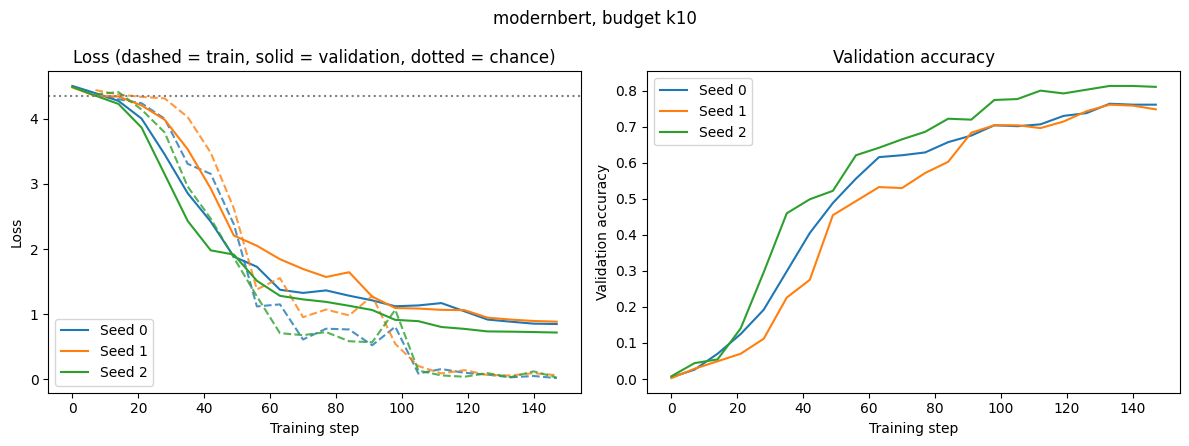

In [12]:
# Loss and validation-accuracy curves for one budget; change the model name and budget to look at another
dg.plot_training_curves("modernbert", "k10", results_dir=RESULTS)

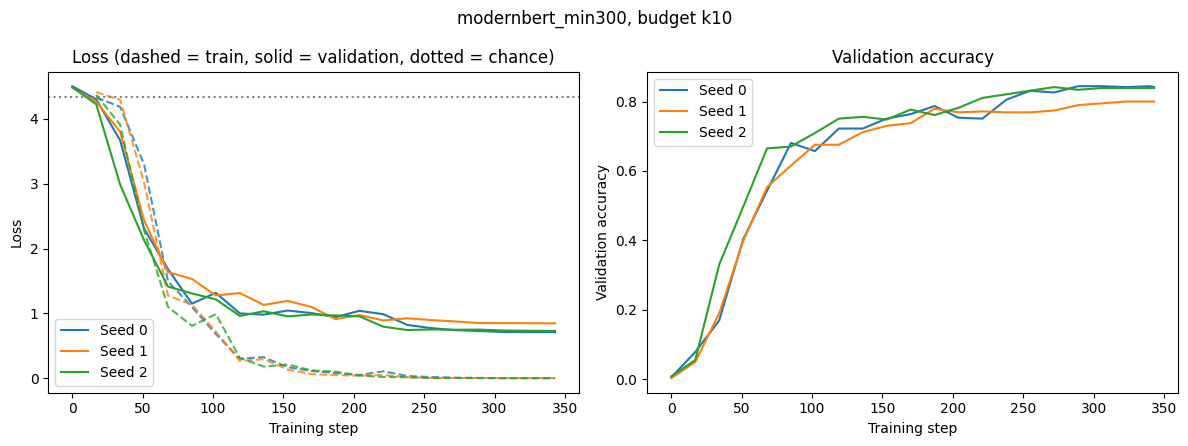

In [13]:
dg.plot_training_curves("modernbert_min300", "k10", results_dir=RESULTS)

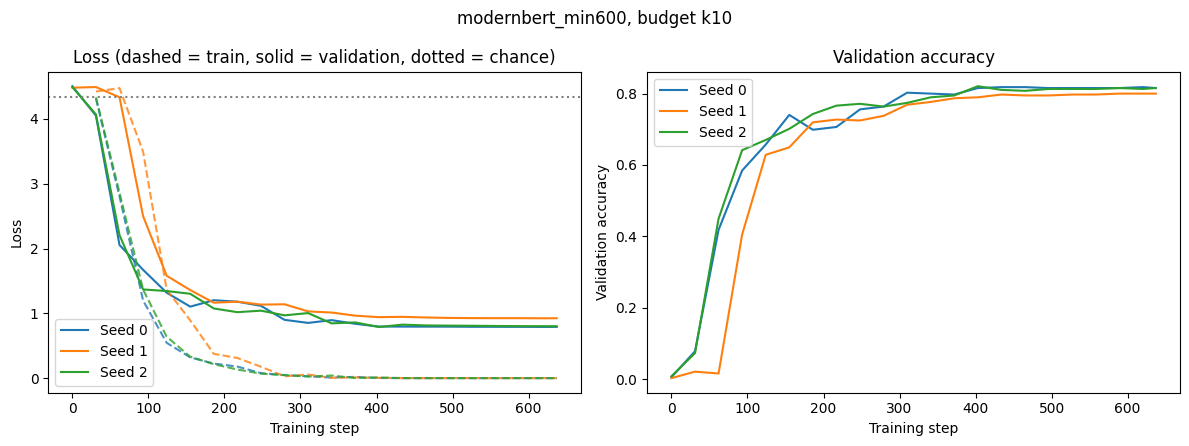

In [14]:
dg.plot_training_curves("modernbert_min600", "k10", results_dir=RESULTS)